# 01. 결과 표 읽기 (재학습 없음)

이 노트북은 저장소에 올라간 작은 결과 표만 읽는다. 서버 자료나 GPU가 필요 없고 아무것도 다시 학습하지 않는다.

- **source 가상 target**: 161개 source 세포주 중 학습에 쓰지 않은 9개 계열을 "처음 보는 세포주"처럼 취급해 채점한 결과다. 모든 설정 선택은 여기서 끝났다.
- **HCC**: 방법을 동결한 뒤 HUH7·JHH5·JHH7에서 한 번 채점한 결과다. 이 자료는 앞선 연구 B에서 이미 채점된 적이 있어 독립 확인이 아니다(`reports/episodic_residual_r2/EXPOSURE.md`).
- 점수 **ΔRMSE**는 "예측한 RNA 변화와 실제 RNA 변화의 차이"이며 **낮을수록 좋다.**
- K는 새 세포주에서 실제로 실험해 본 약물 수(8, 16, 32)다.

In [1]:
import os, json, sys
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
ROOT = os.environ.get("R2_ROOT", os.path.abspath(os.path.join(os.getcwd(), "..", "..")) if os.path.basename(os.getcwd()) == "episodic_residual_r2" else os.getcwd())
os.chdir(ROOT); sys.path.insert(0, ROOT)
pd.set_option("display.width", 200); pd.set_option("display.float_format", lambda v: f"{v:.4f}")
BLUE, ORANGE, AQUA, YELLOW, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8983"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
                     "grid.color": "#e4e3df", "grid.linewidth": 0.6, "axes.edgecolor": "#8a8983", "font.size": 10,
                     "lines.linewidth": 2, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb"})
MAN = "manifests/episodic_residual_r2"
LABEL = {"no_change": "no change", "source_same_drug_mean": "source same-drug mean (f0)", "mean_offset": "f0 + mean offset",
         "shrunk_same_drug_mean": "shrunk f0 (added)", "shrunk_mean_offset": "shrunk f0 + shrunk offset (added)",
         "ecfp_ridge": "ECFP residual ridge", "ecfp_krr": "ECFP Tanimoto KRR", "allfeat_krr": "same-input untrained KRR",
         "generic_cnp": "generic CNP", "residual_adapter": "proposed adapter", "residual_adapter__zero_residual": "proposed, residual set to 0",
         "residual_adapter__shuffle_residual": "proposed, residual rows swapped", "transigen_as_is": "TranSiGen as is",
         "transigen_offset": "TranSiGen + offset", "transigen_full_ft": "TranSiGen full fine-tuning"}
MAIN = ["no_change", "source_same_drug_mean", "mean_offset", "shrunk_same_drug_mean", "shrunk_mean_offset", "ecfp_ridge", "ecfp_krr", "allfeat_krr",
        "generic_cnp", "residual_adapter", "transigen_as_is", "transigen_offset", "transigen_full_ft"]

## 1. source 가상 target: 방법별 ΔRMSE

In [2]:
src = pd.read_csv(f"{MAN}/source_eval_summary.tsv", sep="\t")
t = src[src.method.isin(MAIN)].pivot(index="method", columns="K", values="delta_rmse").reindex(MAIN)
t.index = [LABEL[m] for m in t.index]
print("meta-validation, 9 held-out cell families, family-equal mean of query delta RMSE (lower is better)")
print(t.to_string())

meta-validation, 9 held-out cell families, family-equal mean of query delta RMSE (lower is better)
K                                     8      16     32
no change                         0.5369 0.5369 0.5369
source same-drug mean (f0)        0.5145 0.5145 0.5145
f0 + mean offset                  0.5301 0.5151 0.5078
shrunk f0 (added)                 0.5078 0.5078 0.5078
shrunk f0 + shrunk offset (added) 0.5021 0.4993 0.4969
ECFP residual ridge               0.5298 0.5148 0.5069
ECFP Tanimoto KRR                 0.5300 0.5148 0.5070
same-input untrained KRR          0.5269 0.5117 0.5011
generic CNP                       0.5025 0.5018 0.5012
proposed adapter                  0.5114 0.5045 0.4971
TranSiGen as is                   0.8560 0.8560 0.8560
TranSiGen + offset                0.5519 0.5367 0.5289
TranSiGen full fine-tuning        0.5448 0.5251 0.5068


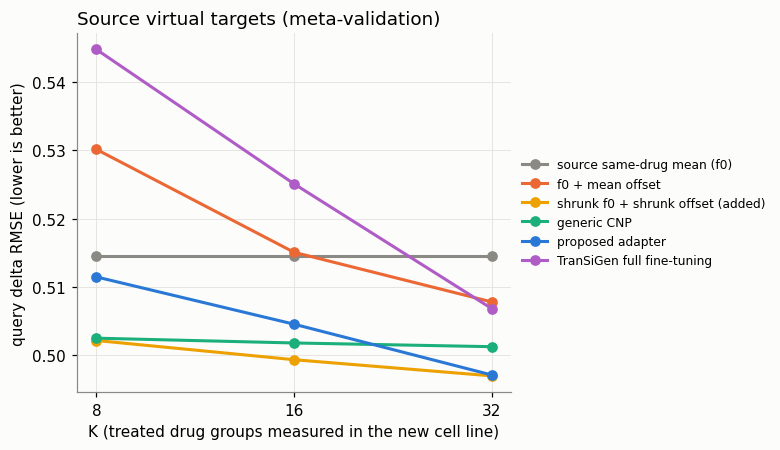

In [3]:
fig, ax = plt.subplots(figsize=(7.2, 4.2))
show = ["source_same_drug_mean", "mean_offset", "shrunk_mean_offset", "generic_cnp", "residual_adapter", "transigen_full_ft"]
cols = [GREY, ORANGE, YELLOW, AQUA, BLUE, "#b05cc6"]
for m, c in zip(show, cols):
    d = src[src.method == m].sort_values("K")
    ax.plot(d.K, d.delta_rmse, marker="o", color=c, label=LABEL[m])
ax.set_xscale("log", base=2); ax.set_xticks([8, 16, 32]); ax.set_xticklabels(["8", "16", "32"])
ax.set_xlabel("K (treated drug groups measured in the new cell line)"); ax.set_ylabel("query delta RMSE (lower is better)")
ax.set_title("Source virtual targets (meta-validation)", loc="left")
ax.legend(frameon=False, fontsize=8, loc="center left", bbox_to_anchor=(1.0, 0.5)); plt.tight_layout(); plt.show()

## 2. 약물별 보정이 실제로 무엇을 더했나

제안법의 예측은 세 조각의 합이다: (1) source 같은 약물 평균 f0, (2) support 평균 잔차(공통 offset), (3) 약물별 보정.
아래 표는 (3)을 0으로 두었을 때와, support 잔차의 짝을 약물끼리 바꿔 넣었을 때의 점수를 함께 보여 준다.
plate를 support와 공유하는 query와 공유하지 않는 query도 나눠 본다.

In [4]:
rows = ["mean_offset", "residual_adapter__zero_residual", "residual_adapter", "residual_adapter__shuffle_residual", "allfeat_krr"]
cols = ["delta_rmse", "delta_rmse_shared_plate", "delta_rmse_disjoint_plate", "centred_pearson", "retrieval_mrr_centred"]
for K in (8, 16, 32):
    d = src[(src.K == K) & src.method.isin(rows)].set_index("method").reindex(rows)[cols]
    d.index = [LABEL[m] for m in d.index]
    print(f"K = {K}"); print(d.to_string()); print()

K = 8
                                 delta_rmse  delta_rmse_shared_plate  delta_rmse_disjoint_plate  centred_pearson  retrieval_mrr_centred
f0 + mean offset                     0.5301                   0.5250                     0.5557           0.2409                 0.4229
proposed, residual set to 0          0.5138                   0.5090                     0.5372           0.2409                 0.4229
proposed adapter                     0.5114                   0.5063                     0.5375           0.2540                 0.4292
proposed, residual rows swapped      0.5200                   0.5153                     0.5408           0.2251                 0.4174
same-input untrained KRR             0.5269                   0.5215                     0.5541           0.2481                 0.4281

K = 16
                                 delta_rmse  delta_rmse_shared_plate  delta_rmse_disjoint_plate  centred_pearson  retrieval_mrr_centred
f0 + mean offset                  

## 3. 동결 후 HCC 평가: 세포주별 ΔRMSE와 95% 구간

In [5]:
hcc = pd.read_csv(f"{MAN}/hcc_results.tsv", sep="\t")
h = hcc[(hcc.query_set == "test") & hcc.method.isin(MAIN)]
for K in (8, 16, 32):
    d = h[h.K == K]
    cell = d.apply(lambda r: f"{r.delta_rmse:.4f} [{r.delta_rmse_lo:.4f}, {r.delta_rmse_hi:.4f}]", axis=1)
    t = d.assign(cell=cell).pivot(index="method", columns="target", values="cell").reindex(MAIN)
    t.index = [LABEL[m] for m in t.index]
    print(f"K = {K}  (test query drug groups; interval = drug-group bootstrap)"); print(t.to_string()); print()

K = 8  (test query drug groups; interval = drug-group bootstrap)
target                                        EQUAL_MEAN_3                     HUH7                     JHH5                     JHH7
no change                          0.6634 [0.6215, 0.7063]  0.7680 [0.6937, 0.8558]  0.5298 [0.5088, 0.5521]  0.6924 [0.5968, 0.7901]
source same-drug mean (f0)         0.6394 [0.6057, 0.6733]  0.7973 [0.7257, 0.8722]  0.5101 [0.4937, 0.5270]  0.6108 [0.5431, 0.6825]
f0 + mean offset                   0.6501 [0.6179, 0.6826]  0.7941 [0.7238, 0.8665]  0.5385 [0.5231, 0.5543]  0.6177 [0.5561, 0.6842]
shrunk f0 (added)                  0.6151 [0.5845, 0.6471]  0.7287 [0.6684, 0.7943]  0.5080 [0.4915, 0.5251]  0.6085 [0.5411, 0.6806]
shrunk f0 + shrunk offset (added)  0.5992 [0.5700, 0.6305]  0.6909 [0.6311, 0.7529]  0.5087 [0.4925, 0.5256]  0.5980 [0.5316, 0.6699]
ECFP residual ridge                0.6504 [0.6179, 0.6831]  0.7954 [0.7245, 0.8675]  0.5385 [0.5232, 0.5544]  0.6173 [0.5556, 0.683

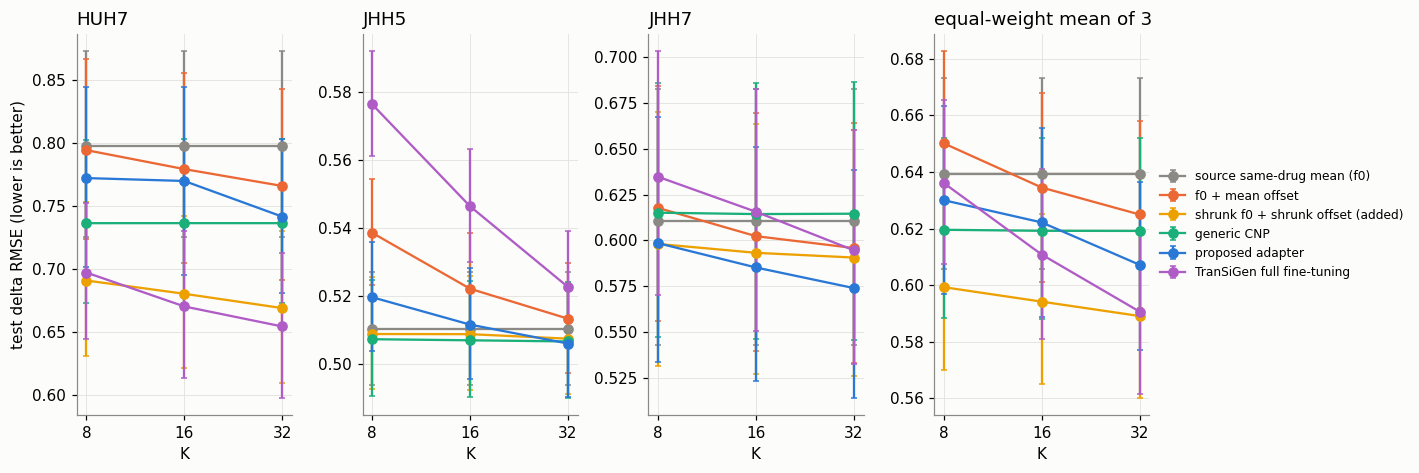

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(13, 4.4), sharey=False)
show = ["source_same_drug_mean", "mean_offset", "shrunk_mean_offset", "generic_cnp", "residual_adapter", "transigen_full_ft"]
cols = [GREY, ORANGE, YELLOW, AQUA, BLUE, "#b05cc6"]
for ax, target in zip(axes, ["HUH7", "JHH5", "JHH7", "EQUAL_MEAN_3"]):
    for m, c in zip(show, cols):
        d = h[(h.target == target) & (h.method == m)].sort_values("K")
        ax.errorbar(d.K, d.delta_rmse, yerr=[d.delta_rmse - d.delta_rmse_lo, d.delta_rmse_hi - d.delta_rmse], marker="o", color=c, capsize=2, label=LABEL[m], linewidth=1.5)
    ax.set_xscale("log", base=2); ax.set_xticks([8, 16, 32]); ax.set_xticklabels(["8", "16", "32"])
    ax.set_title(target if target != "EQUAL_MEAN_3" else "equal-weight mean of 3", loc="left"); ax.set_xlabel("K")
axes[0].set_ylabel("test delta RMSE (lower is better)")
axes[-1].legend(frameon=False, fontsize=8, loc="center left", bbox_to_anchor=(1.0, 0.5)); plt.tight_layout(); plt.show()

## 4. 기준선과의 차이 (같은 query 약물에서의 짝 비교)

`diff`가 음수면 그 방법이 기준선보다 낮다(좋다). 구간이 0을 포함하면 방향을 정할 수 없다.

In [7]:
con = pd.read_csv(f"{MAN}/hcc_contrasts.tsv", sep="\t")
c = con[(con.query_set == "test") & (con.metric == "delta_rmse") & (con.reference == "mean_offset") & con.method.isin(MAIN)]
for K in (8, 16, 32):
    d = c[c.K == K]
    cell = d.apply(lambda r: f"{r['diff']:+.4f} [{r.lo:+.4f}, {r.hi:+.4f}]", axis=1)
    t = d.assign(cell=cell).pivot(index="method", columns="target", values="cell").reindex([m for m in MAIN if m != "mean_offset"])
    t.index = [LABEL[m] for m in t.index]
    print(f"K = {K}: method minus 'f0 + mean offset'"); print(t.to_string()); print()

K = 8: method minus 'f0 + mean offset'
target                                           EQUAL_MEAN_3                        HUH7                        JHH5                        JHH7
no change                          +0.0133 [-0.0147, +0.0422]  -0.0261 [-0.0997, +0.0472]  -0.0087 [-0.0185, +0.0020]  +0.0747 [+0.0350, +0.1154]
source same-drug mean (f0)         -0.0107 [-0.0187, -0.0025]  +0.0032 [-0.0185, +0.0264]  -0.0284 [-0.0310, -0.0259]  -0.0069 [-0.0159, +0.0023]
shrunk f0 (added)                  -0.0350 [-0.0570, -0.0143]  -0.0654 [-0.1311, -0.0042]  -0.0305 [-0.0333, -0.0278]  -0.0092 [-0.0176, -0.0002]
shrunk f0 + shrunk offset (added)  -0.0508 [-0.0731, -0.0309]  -0.1032 [-0.1698, -0.0432]  -0.0297 [-0.0319, -0.0277]  -0.0197 [-0.0262, -0.0128]
ECFP residual ridge                +0.0003 [-0.0000, +0.0006]  +0.0013 [+0.0004, +0.0021]  +0.0000 [-0.0001, +0.0002]  -0.0004 [-0.0008, +0.0000]
ECFP Tanimoto KRR                  +0.0001 [-0.0002, +0.0004]  +0.0007 [-0.0001, +0.0

## 5. 공통 이동을 뺀 지표

ΔRMSE는 모든 약물에 공통인 이동을 맞히기만 해도 좋아진다. 아래는 예측과 정답에서 각각 query 평균을 뺀 뒤의 상관(centred Pearson)과,
"예측이 자기 약물의 정답을 다른 약물의 정답보다 잘 찾는가"(centred MRR, 1에 가까울수록 좋음)다.

In [8]:
for v in ("centred_pearson", "mrr_centred"):
    t = h[h.K == 16].pivot(index="method", columns="target", values=v).reindex(MAIN)
    t.index = [LABEL[m] for m in t.index]
    print(f"K = 16, {v} (higher is better)"); print(t.to_string()); print()

K = 16, centred_pearson (higher is better)
target                             EQUAL_MEAN_3   HUH7   JHH5   JHH7
no change                                   NaN    NaN    NaN    NaN
source same-drug mean (f0)               0.2671 0.1822 0.1884 0.4307
f0 + mean offset                         0.2671 0.1822 0.1884 0.4307
shrunk f0 (added)                        0.2840 0.2321 0.1894 0.4305
shrunk f0 + shrunk offset (added)        0.2840 0.2321 0.1894 0.4305
ECFP residual ridge                      0.2684 0.1820 0.1892 0.4340
ECFP Tanimoto KRR                        0.2685 0.1818 0.1893 0.4344
same-input untrained KRR                 0.2868 0.2025 0.2089 0.4489
generic CNP                              0.2681 0.1634 0.2119 0.4291
proposed adapter                         0.2931 0.2072 0.2139 0.4584
TranSiGen as is                          0.2889 0.2330 0.2247 0.4089
TranSiGen + offset                       0.2889 0.2330 0.2247 0.4089
TranSiGen full fine-tuning               0.3074 0.2831 0.222

## 6. 예측 배열은 어디에 있나

발현 배열은 Git에 올리지 않았다. 서버 경로와 SHA-256만 기록했다.

In [9]:
pf = json.load(open("predictions/episodic_residual_r2/prediction_files.json"))
print("frozen code commit:", pf["frozen_code_commit"][:10], "| eval job:", pf["slurm_job"], "| failures:", len(pf["failures"]))
for name, e in list(pf["prediction_files"].items()):
    print(f"{name:28s} {e['bytes'] / 1e6:6.1f} MB  n_query={e['n_query']:4d}  sha256={e['sha256'][:16]}...")

frozen code commit: a4d0bbabeb | eval job: 25276 | failures: 0
pred_HUH7_split1.npz           12.2 MB  n_query=  28  sha256=c33e0f2541d95e05...
pred_HUH7_split2.npz           12.2 MB  n_query=  28  sha256=0d30a04c18e91588...
pred_HUH7_split3.npz           12.2 MB  n_query=  28  sha256=d052b6e026a9b784...
pred_JHH5_split1.npz          112.4 MB  n_query= 260  sha256=eb9fd73add9086ff...
pred_JHH5_split2.npz          112.5 MB  n_query= 260  sha256=9096515af8efc79a...
pred_JHH5_split3.npz          112.4 MB  n_query= 260  sha256=c21855426c9c8bec...
pred_JHH7_split1.npz           19.1 MB  n_query=  44  sha256=7aded8e1dd3c9ec4...
pred_JHH7_split2.npz           19.1 MB  n_query=  44  sha256=ba225216c52a4e40...
pred_JHH7_split3.npz           19.1 MB  n_query=  44  sha256=005477c64ae2f7e8...
